<p align="center">
  <img src="https://github.com/paulmunozpauta/Curso_Introduccion_Ciencia_Datos/raw/main/Static/Imgs/UdeC_color_horizontal.jpg" width="500">
</p>

<p align="center"><b style="font-size:28px;">Facultad de Ingeniería Agrícola</b></p>
<p align="center"><b style="font-size:28px;">Introducción a la Ciencia de Datos</b></p>
<hr>
<p align="center"><b style="font-size:28px;">Contacto</b></p>
<p align="center">
  paulmunoz@udec.cl<br>
  https://paulmunoz.com
</p>

## Módulo 5: Fundamentos del aprendizaje automático

### Notebook 1: Introducción al aprendizaje automático con Python

En el módulo anterior aprendimos a construir, evaluar e interpretar un modelo de regresión lineal simple. Utilizando los datos meteorológicos de MeteoChillán, estudiamos la relación entre temperatura del aire y humedad relativa, obteniendo una ecuación que permite estimar la humedad relativa a partir de la temperatura.

Encontramos que la regresión lineal explicaba aproximadamente el 75 % de la variabilidad observada. Sin embargo, el análisis de residuos mostró que una recta no representa completamente la relación entre ambas variables.

Esto nos lleva a plantear nuevas preguntas:

- ¿Podemos utilizar otros métodos para representar relaciones que no son estrictamente lineales?
- ¿Cómo aprende un modelo a partir de los datos?
- ¿Cómo podemos comprobar si un modelo funciona correctamente con observaciones que no utilizamos para construirlo?
- ¿Un modelo más complejo necesariamente produce mejores estimaciones?
- ¿Cómo podemos comparar diferentes modelos de manera justa?

Para responder estas preguntas introduciremos los fundamentos del **aprendizaje automático (Machine Learning, ML)**, un conjunto de métodos que permiten identificar patrones en los datos y utilizarlos para realizar estimaciones o predicciones.

En esta actividad nos concentraremos en el **aprendizaje supervisado**, donde los modelos aprenden relaciones entre variables predictoras y una variable objetivo utilizando observaciones conocidas.

Trabajaremos nuevamente con los datos meteorológicos de MeteoChillán, utilizando la temperatura del aire para estimar la humedad relativa.

Compararemos dos modelos:

1. **Regresión lineal:** método estudiado en el módulo anterior, que utilizaremos como modelo de referencia.
2. **Random Forest:** método de aprendizaje automático basado en múltiples árboles de decisión, capaz de representar relaciones no lineales.

A diferencia de la actividad anterior, dividiremos las observaciones en dos conjuntos: **entrenamiento (70 %) y prueba (30 %)**.

Utilizaremos los datos de entrenamiento para ajustar ambos modelos y reservaremos los datos de prueba para evaluar su desempeño con observaciones que no participaron en el entrenamiento.

De esta manera, podremos comparar la capacidad de ambos modelos para estimar la humedad relativa y analizar si Random Forest ofrece ventajas respecto a la regresión lineal.

Los datos utilizados ya fueron sometidos a un control básico de calidad, agregados a resolución horaria y exportados al archivo `MeteoChillan_datos_horarios.csv` en las actividades anteriores.

En este notebook aprenderemos a preparar los datos, entrenar modelos de aprendizaje supervisado y comparar sus resultados utilizando Python y Scikit-learn.

### Al finalizar este notebook podrás:

- Comprender los conceptos básicos del aprendizaje automático supervisado.
- Identificar las variables predictoras y la variable objetivo.
- Explicar la diferencia entre los conjuntos de entrenamiento y prueba.
- Dividir cronológicamente una serie de datos para entrenar y evaluar modelos.
- Ajustar una regresión lineal como modelo de referencia.
- Comprender el funcionamiento de Random Forest y entrenar un modelo de regresión.
- Evaluar el desempeño mediante R², MAE y RMSE.
- Comparar el desempeño de ambos modelos utilizando las mismas observaciones de prueba.
- Identificar posibles problemas de sobreajuste y generalización.
- Reconocer las ventajas y limitaciones de diferentes métodos de aprendizaje automático.

## 1. Importación de librerías

Para desarrollar esta actividad utilizaremos las librerías de Python que ya conocemos, junto con nuevas herramientas de **Scikit-learn**, una biblioteca ampliamente utilizada para implementar modelos de aprendizaje automático.

Las principales librerías serán:

- **Pandas:** importación, organización y manipulación de datos.
- **NumPy:** operaciones numéricas.
- **Matplotlib y Seaborn:** visualización de datos y resultados.
- **Scikit-learn:** entrenamiento de modelos de regresión lineal y Random Forest, y evaluación de su desempeño.

Utilizaremos `LinearRegression` para ajustar nuestro modelo de referencia y `RandomForestRegressor` para construir el modelo basado en árboles de decisión.

También importaremos las métricas R², MAE y RMSE para evaluar y comparar ambos modelos.

In [1]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Modelos de aprendizaje automático
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Métricas de evaluación
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Configuración de gráficos
sns.set_theme(style="whitegrid", context="notebook")

## 2. Importación y exploración de datos

Utilizaremos nuevamente los datos meteorológicos de **MeteoChillán**, correspondientes a observaciones horarias de temperatura, humedad relativa, radiación solar, velocidad del viento y presión atmosférica.

Estos datos fueron preparados en las actividades anteriores, donde realizamos un control básico de calidad, identificamos valores faltantes y agregamos las observaciones a resolución horaria.

Por tanto, no repetiremos el proceso de limpieza y preparación inicial.

Importaremos el archivo `MeteoChillan_datos_horarios.csv` y verificaremos su estructura antes de seleccionar las variables que utilizaremos para entrenar los modelos.

Es importante conservar el índice temporal, ya que posteriormente dividiremos las observaciones de manera cronológica para evitar utilizar información futura durante el entrenamiento.

In [2]:
# Importar archivo CSV desde el computador
from google.colab import files

uploaded = files.upload()

# Leer el archivo
nombre_archivo = next(iter(uploaded))

df_final = pd.read_csv(
    nombre_archivo,
    index_col=0,
    parse_dates=True
)

# Ordenar cronológicamente
df_final = df_final.sort_index()

# Mostrar las primeras observaciones
display(df_final.head())

Saving MeteoChillan_datos_horarios.csv to MeteoChillan_datos_horarios.csv


,Temperatura,Humedad,Radiación,Viento,Presión
datetime_utc,,,,,
2025-12-22 05:00:00+00:00,19.05,57.5,0.0,0.0,997.630494
2025-12-22 06:00:00+00:00,18.60,58.5,0.0,0.0,996.953216
2025-12-22 07:00:00+00:00,18.15,59.5,0.0,0.0,996.783896
2025-12-22 08:00:00+00:00,17.70,60.0,0.0,0.0,997.122536
2025-12-22 09:00:00+00:00,17.30,60.0,0.2,0.0,997.461174


### 2.1. Verificación de los datos

Antes de construir los modelos, revisaremos:

- El número de observaciones disponibles.
- Las variables y sus tipos de datos.
- El periodo temporal de las observaciones.
- La cantidad de valores faltantes.

Esta revisión permite comprobar que los datos se importaron correctamente y que las variables necesarias están disponibles.

In [3]:
# Dimensiones del DataFrame
print(f"Número de observaciones: {df_final.shape[0]}")
print(f"Número de variables: {df_final.shape[1]}")

# Periodo de observación
print(f"\nFecha inicial: {df_final.index.min()}")
print(f"Fecha final: {df_final.index.max()}")

# Información general
print("\nInformación del DataFrame:")
df_final.info()

# Valores faltantes
print("\nValores faltantes por variable:")
display(df_final.isna().sum())

Número de observaciones: 6736
Número de variables: 5

Fecha inicial: 2025-12-22 05:00:00+00:00
Fecha final: 2026-09-28 20:00:00+00:00

Información del DataFrame:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 6736 entries, 2025-12-22 05:00:00+00:00 to 2026-09-28 20:00:00+00:00
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperatura  6398 non-null   float64
 1   Humedad      6398 non-null   float64
 2   Radiación    6398 non-null   float64
 3   Viento       6398 non-null   float64
 4   Presión      6398 non-null   float64
dtypes: float64(5)
memory usage: 315.8 KB

Valores faltantes por variable:


,0
Temperatura,338
Humedad,338
Radiación,338
Viento,338
Presión,338


## 3. Preparación de los datos para aprendizaje supervisado

En el **aprendizaje supervisado**, los modelos aprenden relaciones entre variables a partir de observaciones conocidas.

Para construir un modelo necesitamos identificar dos elementos:

- **Variables predictoras (X o features):** contienen la información que utilizaremos para realizar las estimaciones.
- **Variable objetivo (Y o target):** corresponde a la variable que queremos estimar.

En nuestro caso:

- **X:** temperatura del aire (°C).
- **Y:** humedad relativa (%).

Utilizaremos únicamente estas dos variables para mantener la comparación con la regresión lineal desarrollada en el módulo anterior.

Antes de entrenar los modelos, eliminaremos las observaciones que contengan valores faltantes en cualquiera de estas variables.

Es importante destacar que ambos modelos utilizarán exactamente las mismas observaciones y variables. De esta manera, podremos comparar sus resultados en igualdad de condiciones.

In [4]:
# Seleccionar las variables de interés
df_ml = df_final[["Temperatura", "Humedad"]].copy()

# Eliminar observaciones con valores faltantes
df_ml = df_ml.dropna()

# Definir variables predictoras y objetivo
X = df_ml[["Temperatura"]]
y = df_ml["Humedad"]

# Mostrar dimensiones
print(f"Observaciones originales: {len(df_final)}")
print(f"Observaciones válidas: {len(df_ml)}")
print(f"Observaciones eliminadas: {len(df_final) - len(df_ml)}")

print(f"\nDimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

# Mostrar las primeras observaciones
display(df_ml.head())

Observaciones originales: 6736
Observaciones válidas: 6398
Observaciones eliminadas: 338

Dimensiones de X: (6398, 1)
Dimensiones de y: (6398,)


,Temperatura,Humedad
datetime_utc,,
2025-12-22 05:00:00+00:00,19.05,57.5
2025-12-22 06:00:00+00:00,18.60,58.5
2025-12-22 07:00:00+00:00,18.15,59.5
2025-12-22 08:00:00+00:00,17.70,60.0
2025-12-22 09:00:00+00:00,17.30,60.0


## 4. División de los datos en entrenamiento y prueba

En el notebook anterior ajustamos una regresión lineal utilizando todas las observaciones disponibles. Esto nos permitió estudiar la relación entre temperatura y humedad relativa, pero no evaluar cómo funcionaría el modelo con datos que no participaron en su construcción.

En aprendizaje automático es importante distinguir entre dos etapas:

- **Entrenamiento (training):** utilizamos un conjunto de observaciones para que el modelo aprenda la relación entre las variables.
- **Prueba (testing):** utilizamos observaciones diferentes para evaluar qué tan bien funciona el modelo con datos que no ha visto durante el entrenamiento.

Esta separación permite evaluar la **capacidad de generalización**, es decir, la capacidad de un modelo para realizar estimaciones sobre observaciones que no fueron utilizadas para ajustarlo.

### 4.1. División cronológica de los datos

En esta actividad utilizaremos:

- **70 % de las observaciones para entrenamiento.**
- **30 % de las observaciones para prueba.**

Como trabajamos con datos meteorológicos, que constituyen una serie temporal, mantendremos el orden cronológico:

1. Las primeras observaciones se utilizarán para entrenamiento.
2. Las observaciones más recientes se reservarán para prueba.

No mezclaremos aleatoriamente los datos, ya que queremos evaluar el desempeño de los modelos en un periodo posterior al utilizado para su entrenamiento.

Esta división también tiene una limitación: los periodos de entrenamiento y prueba pueden presentar condiciones meteorológicas y estacionales diferentes, lo que puede influir en los resultados.

**Importante:** tanto la regresión lineal como Random Forest utilizarán exactamente los mismos conjuntos de entrenamiento y prueba. Esto permitirá realizar una comparación justa entre ambos modelos. Además, como disponemos de menos de un año de observaciones meteorológicas, los periodos de entrenamiento y prueba pueden presentar condiciones estacionales diferentes. Esto podría influir en el desempeño de los modelos. Por tanto, los resultados deben interpretarse considerando esta limitación.

In [5]:
# Porcentaje de entrenamiento
train_ratio = 0.70

# Número de observaciones de entrenamiento
n_train = int(len(df_ml) * train_ratio)

# División cronológica
X_train = X.iloc[:n_train]
X_test = X.iloc[n_train:]

y_train = y.iloc[:n_train]
y_test = y.iloc[n_train:]

# Resumen
print(f"Observaciones totales: {len(X)}")
print(f"Entrenamiento: {len(X_train)} ({len(X_train)/len(X)*100:.1f} %)")
print(f"Prueba: {len(X_test)} ({len(X_test)/len(X)*100:.1f} %)")

print("\nPeriodo de entrenamiento:")
print(f"{X_train.index.min()} → {X_train.index.max()}")

print("\nPeriodo de prueba:")
print(f"{X_test.index.min()} → {X_test.index.max()}")

Observaciones totales: 6398
Entrenamiento: 4478 (70.0 %)
Prueba: 1920 (30.0 %)

Periodo de entrenamiento:
2025-12-22 05:00:00+00:00 → 2026-07-06 12:00:00+00:00

Periodo de prueba:
2026-07-06 13:00:00+00:00 → 2026-09-28 20:00:00+00:00


### 4.2. Visualización de los conjuntos de entrenamiento y prueba

Antes de ajustar los modelos, visualizaremos cómo se distribuyen las observaciones de entrenamiento y prueba a lo largo del tiempo.

Esto nos permitirá comprobar que la división se realizó correctamente y observar si existen diferencias entre ambos periodos.

En particular, es importante recordar que las variables meteorológicas presentan variaciones estacionales. Por tanto, el periodo de prueba podría contener condiciones diferentes a las utilizadas durante el entrenamiento.

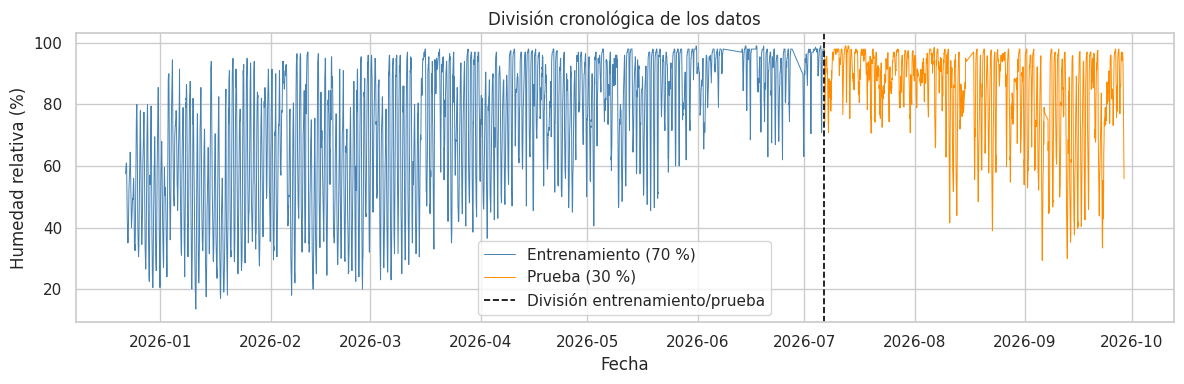

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    y_train.index,
    y_train,
    color="steelblue",
    linewidth=0.7,
    label="Entrenamiento (70 %)"
)

ax.plot(
    y_test.index,
    y_test,
    color="darkorange",
    linewidth=0.7,
    label="Prueba (30 %)"
)

ax.axvline(
    X_test.index.min(),
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="División entrenamiento/prueba"
)

ax.set_xlabel("Fecha")
ax.set_ylabel("Humedad relativa (%)")
ax.set_title("División cronológica de los datos")
ax.legend()

plt.tight_layout()
plt.show()

## 5. Regresión lineal como modelo de referencia

En el módulo anterior aprendimos a construir una regresión lineal simple mediante el método de mínimos cuadrados. Utilizamos todas las observaciones disponibles para estudiar la relación entre temperatura del aire y humedad relativa.

Ahora utilizaremos nuevamente la regresión lineal, pero con una diferencia importante: **el modelo se ajustará únicamente con las observaciones de entrenamiento (70 %)**.

La regresión lineal será nuestro **modelo de referencia (baseline)**. Sus resultados nos permitirán evaluar posteriormente si Random Forest ofrece alguna mejora.

Para construir el modelo utilizaremos `LinearRegression` de Scikit-learn.

El procedimiento consiste en tres pasos:

1. **Crear el modelo:** definir el algoritmo que utilizaremos.
2. **Entrenar el modelo (`fit`):** calcular los coeficientes utilizando los datos de entrenamiento.
3. **Realizar estimaciones (`predict`):** aplicar el modelo entrenado para estimar la humedad relativa.

La ecuación del modelo es la misma que estudiamos anteriormente:

$$
\widehat{Y} = b_0 + b_1 X
$$

Donde:

- $\widehat{Y}$: humedad relativa estimada (%).
- $X$: temperatura del aire (°C).
- $b_0$: intercepto.
- $b_1$: pendiente.

Los coeficientes pueden ser diferentes a los obtenidos en el módulo anterior porque ahora utilizaremos únicamente el conjunto de entrenamiento.

In [8]:
# Crear el modelo de regresión lineal
modelo_lr = LinearRegression()

# Entrenar utilizando únicamente el 70 % de los datos
modelo_lr.fit(X_train, y_train)

# Obtener los coeficientes
b0 = modelo_lr.intercept_
b1 = modelo_lr.coef_[0]

print("Modelo de regresión lineal")
print(f"Intercepto (b0): {b0:.4f}")
print(f"Pendiente (b1): {b1:.4f}")

print(f"\nHumedad estimada = {b0:.4f} + ({b1:.4f}) × Temperatura")

Modelo de regresión lineal
Intercepto (b0): 109.9582
Pendiente (b1): -2.5098

Humedad estimada = 109.9582 + (-2.5098) × Temperatura


### 5.1. Estimaciones con el modelo entrenado

Una vez entrenado el modelo, podemos utilizarlo para estimar la humedad relativa.

Scikit-learn proporciona el método `predict()`, que recibe las variables predictoras y devuelve las estimaciones correspondientes.

Calcularemos las estimaciones para dos conjuntos:

- **Entrenamiento:** permite observar qué tan bien representa el modelo los datos utilizados para ajustarlo.
- **Prueba:** permite evaluar su desempeño con observaciones que no participaron en el entrenamiento.

Es importante distinguir ambos resultados. Un modelo puede representar adecuadamente los datos de entrenamiento, pero presentar errores mayores cuando se aplica a observaciones nuevas.

Posteriormente calcularemos R², MAE y RMSE para comparar el desempeño de la regresión lineal y Random Forest.

In [9]:
# Estimaciones para entrenamiento
y_train_pred_lr = modelo_lr.predict(X_train)

# Estimaciones para prueba
y_test_pred_lr = modelo_lr.predict(X_test)

# Comparar observaciones y estimaciones del conjunto de prueba
df_pred_lr = pd.DataFrame({
    "Humedad observada": y_test,
    "Humedad estimada": y_test_pred_lr
}, index=y_test.index)

display(df_pred_lr.head(10))

,Humedad observada,Humedad estimada
datetime_utc,,
2026-07-06 13:00:00+00:00,98.000000,112.990897
2026-07-06 14:00:00+00:00,98.000000,110.376518
2026-07-06 15:00:00+00:00,98.000000,106.423578
2026-07-06 16:00:00+00:00,96.666667,100.253644
2026-07-06 17:00:00+00:00,79.750000,93.017044
2026-07-06 18:00:00+00:00,74.416667,88.185672
2026-07-06 19:00:00+00:00,77.833333,88.311162
2026-07-06 20:00:00+00:00,81.166667,89.398744
2026-07-06 21:00:00+00:00,83.583333,91.343842


### 5.2. Visualización de la regresión lineal

Representaremos las observaciones de entrenamiento y prueba junto con la recta de regresión obtenida utilizando únicamente los datos de entrenamiento.

Esta figura permitirá identificar:

- Las observaciones utilizadas para ajustar el modelo.
- Las observaciones reservadas para evaluar su desempeño.
- La relación lineal aprendida por el modelo.

La recta se obtiene a partir de los coeficientes calculados durante el entrenamiento. No se vuelve a ajustar utilizando los datos de prueba.

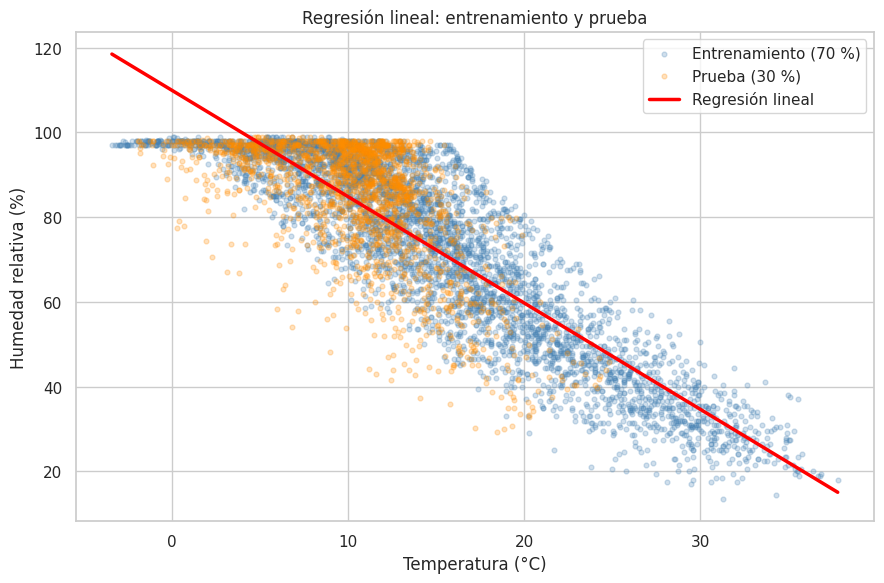

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))

# Observaciones de entrenamiento
ax.scatter(
    X_train["Temperatura"],
    y_train,
    alpha=0.25,
    s=12,
    color="steelblue",
    label="Entrenamiento (70 %)"
)

# Observaciones de prueba
ax.scatter(
    X_test["Temperatura"],
    y_test,
    alpha=0.25,
    s=12,
    color="darkorange",
    label="Prueba (30 %)"
)

# Recta de regresión (dos puntos son suficientes)
x_recta = np.array([
    X["Temperatura"].min(),
    X["Temperatura"].max()
])

y_recta = b0 + b1 * x_recta

ax.plot(
    x_recta,
    y_recta,
    color="red",
    linewidth=2.5,
    label="Regresión lineal"
)

ax.set_xlabel("Temperatura (°C)")
ax.set_ylabel("Humedad relativa (%)")
ax.set_title("Regresión lineal: entrenamiento y prueba")
ax.legend()

plt.tight_layout()
plt.show()

**Un detalle importante:** aunque la regresión lineal es un método estadístico clásico, también se considera un algoritmo de aprendizaje automático supervisado cuando se utiliza para aprender relaciones a partir de datos y realizar estimaciones sobre nuevas observaciones.

## 6. Introducción a Random Forest

En la sección anterior ajustamos una regresión lineal para estimar la humedad relativa a partir de la temperatura del aire.

La regresión lineal representa la relación entre ambas variables mediante una recta. Sin embargo, como observamos en el módulo anterior, las relaciones entre variables ambientales no siempre son lineales.

Por ejemplo, la humedad relativa puede responder de manera diferente a los cambios de temperatura dependiendo de las condiciones meteorológicas.

Esto nos lleva a una nueva pregunta:

**¿Podemos construir un modelo que aprenda relaciones no lineales sin definir previamente una ecuación?**

Una alternativa es **Random Forest**, un algoritmo de aprendizaje automático supervisado basado en árboles de decisión.

### 6.1. ¿Qué es un árbol de decisión?

Un árbol de decisión es un modelo que divide progresivamente las observaciones en grupos utilizando condiciones sobre las variables predictoras.

En nuestro caso, el modelo podría identificar reglas como:

- Si la temperatura es menor o igual a 10 °C, las observaciones pertenecen a un grupo.
- Si la temperatura es mayor a 10 °C, pertenecen a otro grupo.
- Cada grupo puede dividirse nuevamente utilizando otros umbrales de temperatura.

Estas divisiones permiten identificar grupos de observaciones con características similares.

En un **árbol de regresión**, la estimación final corresponde generalmente al promedio de los valores observados de la variable objetivo dentro del grupo terminal.

Por tanto, a diferencia de la regresión lineal, un árbol de decisión no necesita representar la relación mediante una recta.

### 6.2. ¿Cómo funciona Random Forest?

Random Forest combina múltiples árboles de decisión para construir un modelo más estable.

Su funcionamiento puede resumirse en cuatro pasos:

1. Se generan diferentes muestras de las observaciones de entrenamiento mediante selección aleatoria con reemplazo (*bootstrap*).
2. Se construye un árbol de decisión utilizando cada muestra.
3. Cada árbol produce una estimación de la humedad relativa.
4. Random Forest calcula el promedio de las estimaciones de todos los árboles.

Por ejemplo, si tres árboles estiman una humedad relativa de 70 %, 74 % y 72 %, la estimación promedio será:

$$
\widehat{Y}_{RF} = \frac{70+74+72}{3}=72\%
$$

En general, la estimación de Random Forest se expresa como:

$$
\widehat{Y}_{RF}(X)=\frac{1}{B}\sum_{b=1}^{B}\widehat{Y}_b(X)
$$

Donde:

- $B$: número de árboles.
- $\widehat{Y}_b(X)$: estimación del árbol $b$.
- $\widehat{Y}_{RF}(X)$: estimación final de Random Forest.

Además del muestreo de observaciones, Random Forest puede seleccionar aleatoriamente un subconjunto de variables predictoras al buscar las divisiones de cada árbol.

En nuestro ejercicio utilizaremos una sola variable predictora (temperatura), por lo que esta segunda fuente de aleatoriedad será limitada.

### 6.3. Diferencias respecto a la regresión lineal

| Característica | Regresión lineal | Random Forest |
|---|---|---|
| Relación entre variables | Lineal | Puede ser no lineal |
| Funcionamiento | Ajusta una ecuación | Combina árboles de decisión |
| Interpretación | Coeficientes de regresión | Reglas y divisiones |
| Extrapolación | Puede extrapolar | Generalmente no extrapola |
| Complejidad | Baja | Mayor |
| Riesgo de sobreajuste | Existe | Existe |

**Importante:** Random Forest no necesariamente producirá mejores estimaciones que la regresión lineal. Su desempeño dependerá de las características de los datos, la configuración del modelo y su capacidad de generalización.

A continuación, entrenaremos Random Forest utilizando exactamente las mismas observaciones de entrenamiento que utilizamos para ajustar la regresión lineal.

### 6.4. Entrenamiento de Random Forest

Utilizaremos `RandomForestRegressor` de Scikit-learn para construir nuestro modelo.

Definiremos tres parámetros:

- **`n_estimators=100`:** número de árboles que formarán el bosque.
- **`random_state=42`:** semilla aleatoria que permite reproducir los resultados.
- **`min_samples_leaf=5`:** número mínimo de observaciones que debe contener cada nodo terminal. Este parámetro ayuda a evitar divisiones excesivamente específicas.

Al igual que con la regresión lineal, utilizaremos el método `fit()` para entrenar el modelo y `predict()` para obtener estimaciones.

El modelo utilizará únicamente las observaciones de entrenamiento. Los datos de prueba permanecerán separados hasta la evaluación.

In [12]:
# Crear el modelo Random Forest
modelo_rf = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Entrenar el modelo
modelo_rf.fit(X_train, y_train)

# Realizar estimaciones
y_train_pred_rf = modelo_rf.predict(X_train)
y_test_pred_rf = modelo_rf.predict(X_test)

print("Modelo Random Forest entrenado correctamente")
print(f"Número de árboles: {modelo_rf.n_estimators}")
print(f"Observaciones de entrenamiento: {len(X_train)}")
print(f"Observaciones de prueba: {len(X_test)}")

Modelo Random Forest entrenado correctamente
Número de árboles: 300
Observaciones de entrenamiento: 4478
Observaciones de prueba: 1920


## 7. Evaluación y comparación de modelos

Ya hemos entrenado dos modelos para estimar la humedad relativa a partir de la temperatura del aire:

1. **Regresión lineal:** ajustada mediante mínimos cuadrados ordinarios.
2. **Random Forest:** construido a partir de 300 árboles de decisión.

Ambos modelos utilizaron las mismas observaciones de entrenamiento (70 %) y realizaron estimaciones sobre el mismo conjunto de prueba (30 %).

Ahora necesitamos determinar qué tan precisas son sus estimaciones.

### 7.1. Métricas de evaluación

Utilizaremos las tres métricas estudiadas en el módulo anterior:

- **Coeficiente de determinación (R²):** mide qué tan bien las estimaciones representan la variabilidad observada. Un valor de 1 indica un ajuste perfecto. En datos de prueba puede tomar valores negativos.
- **Error absoluto medio (MAE):** representa la magnitud promedio de los errores absolutos. Se expresa en puntos porcentuales de humedad relativa.
- **Raíz del error cuadrático medio (RMSE):** mide la magnitud de los errores, penalizando especialmente los errores grandes. También se expresa en puntos porcentuales.

Para interpretar los resultados:

- **R²:** valores más altos indican un mejor desempeño.
- **MAE:** valores más bajos indican errores menores.
- **RMSE:** valores más bajos indican errores menores, especialmente cuando existen errores grandes.

### 7.2. ¿Por qué evaluar entrenamiento y prueba?

Calcularemos las métricas para ambos conjuntos.

**Evaluación en entrenamiento**

Permite conocer qué tan bien representa cada modelo las observaciones utilizadas durante su ajuste.

**Evaluación en prueba**

Permite evaluar cómo funcionan los modelos con observaciones que no participaron en el entrenamiento.

Esta segunda evaluación es especialmente importante porque nos ayuda a identificar si un modelo ha aprendido relaciones que pueden generalizarse a nuevas observaciones.

Un modelo puede presentar excelentes resultados en entrenamiento y errores considerablemente mayores en prueba. Este comportamiento puede indicar **sobreajuste (overfitting)**.

Por tanto, no seleccionaremos el mejor modelo únicamente por su desempeño en entrenamiento.

**Nuestro principal criterio de comparación será el desempeño sobre los datos de prueba.**

In [13]:
# Función para calcular las métricas de evaluación
def evaluar_modelo(y_obs, y_pred):

    r2 = r2_score(y_obs, y_pred)
    mae = mean_absolute_error(y_obs, y_pred)
    rmse = np.sqrt(mean_squared_error(y_obs, y_pred))

    return {
        "R²": r2,
        "MAE": mae,
        "RMSE": rmse
    }


# Evaluación de ambos modelos
resultados = pd.DataFrame({
    "Regresión lineal - Entrenamiento": evaluar_modelo(
        y_train, y_train_pred_lr
    ),
    "Regresión lineal - Prueba": evaluar_modelo(
        y_test, y_test_pred_lr
    ),
    "Random Forest - Entrenamiento": evaluar_modelo(
        y_train, y_train_pred_rf
    ),
    "Random Forest - Prueba": evaluar_modelo(
        y_test, y_test_pred_rf
    )
}).T

# Mostrar resultados
display(resultados.round(3))

,R²,MAE,RMSE
Regresión lineal - Entrenamiento,0.804,7.855,9.744
Regresión lineal - Prueba,0.354,9.634,11.795
Random Forest - Entrenamiento,0.854,6.371,8.427
Random Forest - Prueba,0.434,8.370,11.047


### 7.3. Interpretación de los resultados

La tabla anterior permite comparar el desempeño de ambos modelos durante el entrenamiento y la prueba.

Para interpretar los resultados, debemos responder las siguientes preguntas:

1. **¿Qué modelo presenta el mayor R² en entrenamiento?** ¿Ocurre lo mismo en prueba?

2. **¿Qué modelo presenta los menores valores de MAE y RMSE en prueba?**

3. **¿Cuánto cambia el desempeño de cada modelo entre entrenamiento y prueba?**

4. **¿Random Forest mejora las estimaciones respecto a la regresión lineal?**

5. **¿Un mejor desempeño en entrenamiento garantiza un mejor desempeño en prueba?**

Es importante recordar que Random Forest es un modelo más flexible que la regresión lineal. Esta flexibilidad puede permitirle representar relaciones no lineales, pero también puede aumentar el riesgo de sobreajuste.

Además, como los datos de entrenamiento y prueba corresponden a periodos diferentes del año, las diferencias de desempeño también pueden estar relacionadas con cambios estacionales.

Por tanto, debemos interpretar los resultados considerando tanto la complejidad de los modelos como las características de los datos utilizados.

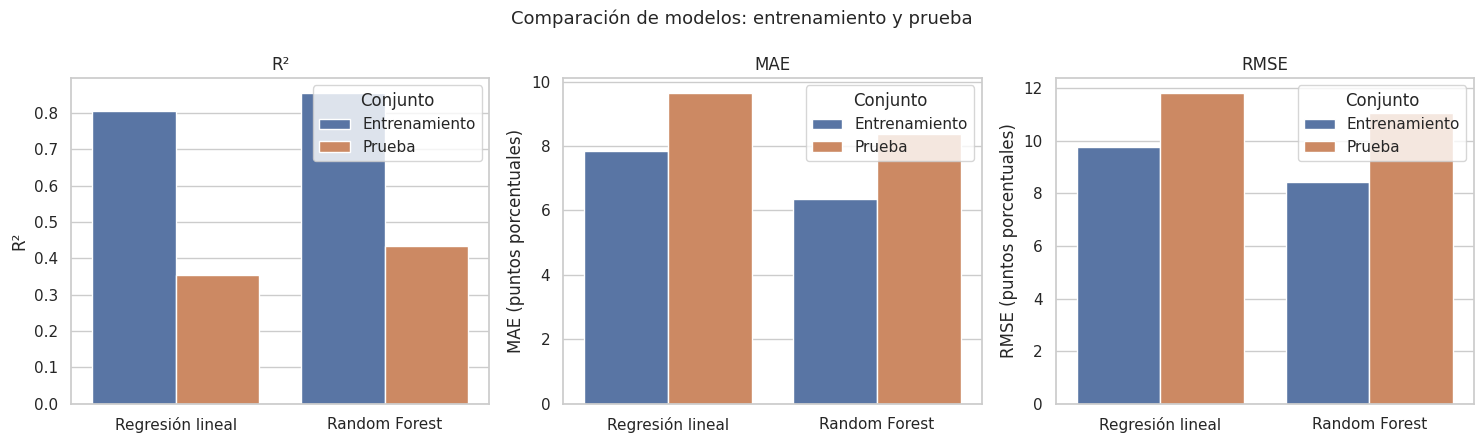

In [14]:
# Organizar resultados para graficar
resultados_plot = resultados.reset_index().rename(
    columns={"index": "Modelo"}
)

resultados_plot["Algoritmo"] = [
    "Regresión lineal",
    "Regresión lineal",
    "Random Forest",
    "Random Forest"
]

resultados_plot["Conjunto"] = [
    "Entrenamiento",
    "Prueba",
    "Entrenamiento",
    "Prueba"
]

# Crear gráficos
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

metricas = ["R²", "MAE", "RMSE"]

for ax, metrica in zip(axes, metricas):

    sns.barplot(
        data=resultados_plot,
        x="Algoritmo",
        y=metrica,
        hue="Conjunto",
        ax=ax
    )

    ax.set_title(metrica)
    ax.set_xlabel("")
    ax.set_ylabel(metrica if metrica == "R²" else f"{metrica} (puntos porcentuales)")
    ax.legend(title="Conjunto")

plt.suptitle(
    "Comparación de modelos: entrenamiento y prueba",
    fontsize=13
)

plt.tight_layout()
plt.show()

Los resultados muestran diferencias importantes entre los modelos y entre los conjuntos de entrenamiento y prueba.

**Regresión lineal**

- En entrenamiento obtuvo un R² de 0.804, un MAE de 7.855 y un RMSE de 9.744.

- En prueba, el R² disminuyó a 0.354, mientras que el MAE aumentó a 9.634 y el RMSE a 11.795.

- Esto indica que el modelo presenta mayores dificultades para representar las observaciones del periodo de prueba.

**Random Forest**

- En entrenamiento obtuvo un R² de 0.854, un MAE de 6.371 y un RMSE de 8.427.

- En prueba, el R² disminuyó a 0.434, mientras que el MAE aumentó a 8.370 y el RMSE a 11.047.

- Random Forest obtuvo mejores resultados que la regresión lineal en las tres métricas, tanto en entrenamiento como en prueba.

**Comparación de modelos**

En el conjunto de prueba, Random Forest redujo el MAE aproximadamente un 13.1 % y el RMSE un 6.3 % respecto a la regresión lineal.

Esto indica que Random Forest consigue representar mejor la relación entre temperatura y humedad relativa para las observaciones evaluadas.

Sin embargo, ambos modelos presentan una reducción considerable de desempeño entre entrenamiento y prueba.

Esta diferencia puede estar relacionada con varios factores:

- Las diferencias estacionales entre los periodos de entrenamiento y prueba.

- La presencia de relaciones que no pueden explicarse utilizando únicamente la temperatura.

- Las limitaciones de cada modelo para representar condiciones diferentes a las observadas durante el entrenamiento.

- El posible sobreajuste a las observaciones de entrenamiento.

Por tanto, una reducción de desempeño en prueba no demuestra por sí sola que exista sobreajuste.

**Conclusión:** Random Forest presenta mejores resultados que la regresión lineal en este ejercicio, pero ninguno de los modelos representa completamente la variabilidad de la humedad relativa durante el periodo de prueba.

Estos resultados muestran que utilizar un modelo más complejo puede mejorar las estimaciones, aunque no garantiza un desempeño elevado con observaciones nuevas.

## 8. Visualización y comparación de las estimaciones

En la sección anterior observamos que Random Forest obtuvo mejores resultados que la regresión lineal en el conjunto de prueba.

Sin embargo, las métricas R², MAE y RMSE no permiten identificar por sí solas cómo se comportan las estimaciones de cada modelo.

Para comprender mejor las diferencias, construiremos dos visualizaciones:

1. **Relación temperatura–humedad:** compararemos la recta de regresión lineal con las estimaciones de Random Forest.
2. **Serie temporal:** compararemos la humedad relativa observada con las estimaciones de ambos modelos durante el periodo de prueba.

### 8.1. Comparación de las relaciones aprendidas

La regresión lineal representa la relación entre temperatura y humedad relativa mediante una recta.

Random Forest, en cambio, utiliza árboles de decisión para identificar diferentes intervalos de temperatura y asignar estimaciones a cada uno.

Esto permite representar relaciones no lineales sin establecer previamente una ecuación.

Para visualizar estas diferencias, generaremos una secuencia de temperaturas y utilizaremos ambos modelos para estimar la humedad relativa correspondiente.

**Importante:** las curvas representan las relaciones aprendidas durante el entrenamiento. No se ajustarán nuevamente utilizando los datos de prueba.

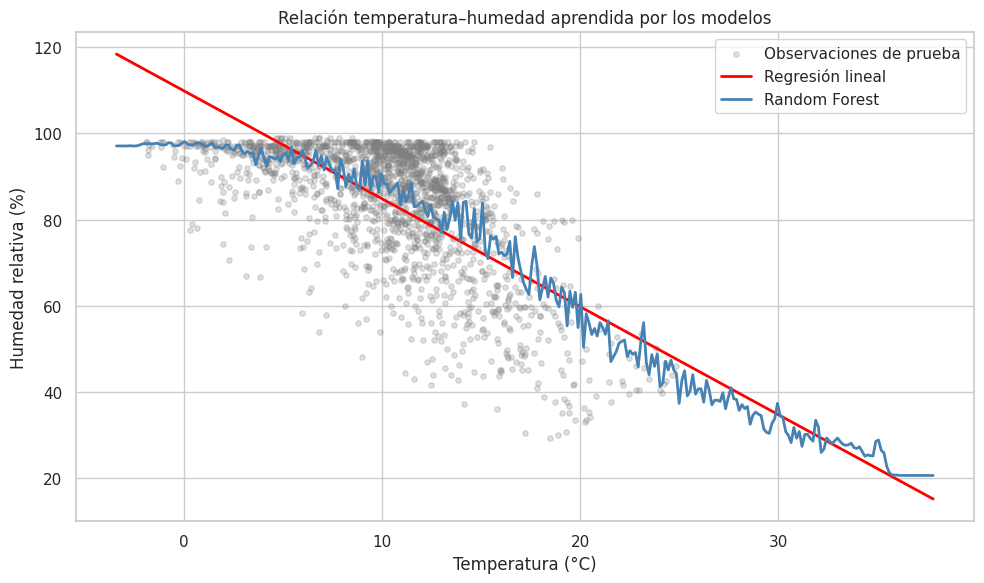

In [15]:
# Crear una secuencia de temperaturas
temperaturas = np.linspace(
    X["Temperatura"].min(),
    X["Temperatura"].max(),
    300
)

# Crear DataFrame con el mismo nombre de variable utilizado en entrenamiento
X_grafico = pd.DataFrame({
    "Temperatura": temperaturas
})

# Obtener estimaciones de ambos modelos
humedad_lr = modelo_lr.predict(X_grafico)
humedad_rf = modelo_rf.predict(X_grafico)

# Crear figura
fig, ax = plt.subplots(figsize=(10, 6))

# Observaciones del conjunto de prueba
ax.scatter(
    X_test["Temperatura"],
    y_test,
    color="gray",
    alpha=0.25,
    s=15,
    label="Observaciones de prueba"
)

# Regresión lineal
ax.plot(
    temperaturas,
    humedad_lr,
    color="red",
    linewidth=2,
    label="Regresión lineal"
)

# Random Forest
ax.plot(
    temperaturas,
    humedad_rf,
    color="steelblue",
    linewidth=2,
    label="Random Forest"
)

ax.set_xlabel("Temperatura (°C)")
ax.set_ylabel("Humedad relativa (%)")
ax.set_title("Relación temperatura–humedad aprendida por los modelos")
ax.legend()

plt.tight_layout()
plt.show()

### 8.2. Interpretación de las relaciones aprendidas

En la figura anterior podemos identificar dos comportamientos diferentes:

**Regresión lineal**

- Representa la relación mediante una recta.
- La pendiente es constante para cualquier temperatura.
- Puede generar estimaciones fuera del intervalo de valores observados durante el entrenamiento.

**Random Forest**

- Representa la relación mediante una sucesión de valores que pueden cambiar entre intervalos de temperatura.
- No necesita asumir una relación lineal.
- Puede identificar cambios en la humedad relativa asociados con diferentes rangos de temperatura.
- Sus estimaciones generalmente permanecen dentro del rango de valores de humedad observado durante el entrenamiento.

Aunque Random Forest es más flexible, esto no significa que necesariamente represente mejor todas las observaciones.

Además, debemos considerar que ambos modelos utilizan únicamente la temperatura como variable predictora.

Por tanto, para una misma temperatura, cada modelo produce una única estimación de humedad relativa, aunque en la realidad puedan observarse valores de humedad muy diferentes bajo distintas condiciones meteorológicas.

**Pregunta para reflexionar:**

¿Por qué dos observaciones con la misma temperatura pueden presentar valores diferentes de humedad relativa?

### 8.3. Comparación temporal de las estimaciones

Además de comparar la relación entre temperatura y humedad relativa, es importante observar cómo se comportan las estimaciones a lo largo del tiempo.

Representaremos tres series:

- **Humedad observada:** valores registrados por la estación meteorológica.
- **Regresión lineal:** estimaciones del modelo lineal.
- **Random Forest:** estimaciones del modelo basado en árboles de decisión.

Utilizaremos los primeros 14 días del conjunto de prueba para visualizar las diferencias con mayor claridad.

Esta figura permitirá identificar:

1. Si los modelos reproducen las variaciones temporales de humedad relativa.
2. En qué momentos se producen las mayores diferencias respecto a las observaciones.
3. Si Random Forest representa mejor los valores altos y bajos de humedad relativa.

La visualización corresponde únicamente a una parte del periodo de prueba. Las métricas calculadas anteriormente consideran todas las observaciones de dicho periodo.

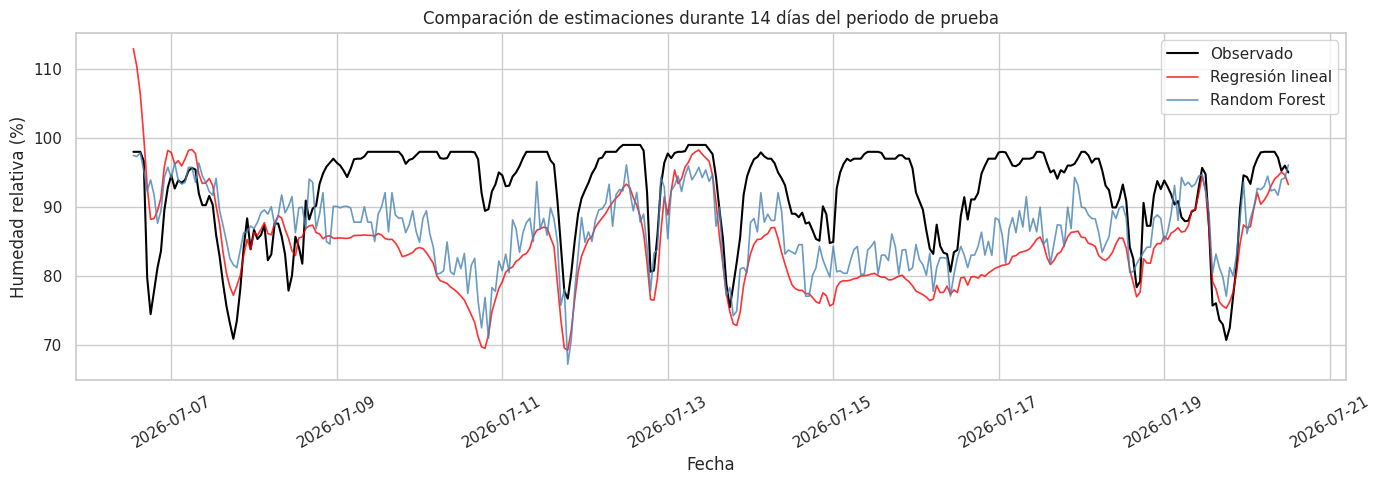

In [16]:
# Crear DataFrame con observaciones y estimaciones
df_comparacion = pd.DataFrame({
    "Observado": y_test,
    "Regresión lineal": y_test_pred_lr,
    "Random Forest": y_test_pred_rf
}, index=y_test.index)

# Seleccionar los primeros 14 días
fecha_inicio = df_comparacion.index.min()
fecha_fin = fecha_inicio + pd.Timedelta(days=14)

df_14dias = df_comparacion.loc[
    (df_comparacion.index >= fecha_inicio) &
    (df_comparacion.index < fecha_fin)
]

# Crear figura
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_14dias.index,
    df_14dias["Observado"],
    color="black",
    linewidth=1.5,
    label="Observado"
)

ax.plot(
    df_14dias.index,
    df_14dias["Regresión lineal"],
    color="red",
    linewidth=1.2,
    alpha=0.8,
    label="Regresión lineal"
)

ax.plot(
    df_14dias.index,
    df_14dias["Random Forest"],
    color="steelblue",
    linewidth=1.2,
    alpha=0.8,
    label="Random Forest"
)

ax.set_xlabel("Fecha")
ax.set_ylabel("Humedad relativa (%)")
ax.set_title("Comparación de estimaciones durante 14 días del periodo de prueba")
ax.legend()

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 8.4. Análisis de las estimaciones

A partir de las dos figuras anteriores, responde las siguientes preguntas:

1. ¿Qué diferencias observas entre la recta de regresión lineal y la relación aprendida por Random Forest?

2. ¿Random Forest representa una relación completamente continua o presenta cambios escalonados? ¿Por qué?

3. En la serie temporal, ¿ambos modelos reproducen adecuadamente los aumentos y disminuciones de humedad relativa?

4. ¿Qué ocurre cuando la humedad relativa observada alcanza valores muy altos o muy bajos?

5. ¿Por qué Random Forest puede presentar mejores métricas de evaluación y, aun así, cometer errores importantes en determinadas observaciones?

**Reflexión final**

Los resultados muestran que Random Forest puede mejorar las estimaciones respecto a la regresión lineal, pero la complejidad del algoritmo no elimina las limitaciones de los datos.

La humedad relativa depende de diferentes procesos atmosféricos. Utilizar únicamente la temperatura permite representar parte de su variabilidad, pero no necesariamente toda.

Esto demuestra que el desempeño de un modelo de aprendizaje automático depende tanto del algoritmo utilizado como de la información disponible para entrenarlo.

## 9. Generalización, sobreajuste y limitaciones de los modelos

Hasta ahora hemos entrenado y evaluado dos modelos de aprendizaje automático para estimar la humedad relativa a partir de la temperatura del aire.

Los resultados mostraron que Random Forest obtuvo mejores métricas que la regresión lineal. Sin embargo, ambos modelos presentaron una reducción importante de desempeño entre entrenamiento y prueba.

¿Por qué ocurre esto?

### 9.1. Generalización

La **generalización** es la capacidad de un modelo para realizar estimaciones adecuadas sobre observaciones que no fueron utilizadas durante su entrenamiento.

En aprendizaje automático, nuestro objetivo no es únicamente obtener buenos resultados con los datos conocidos, sino construir modelos que también funcionen con observaciones nuevas.

En nuestro ejercicio obtuvimos:

| Modelo | R² entrenamiento | R² prueba |
|---|---:|---:|
| Regresión lineal | 0.804 | 0.354 |
| Random Forest | 0.854 | 0.434 |

Ambos modelos presentan mejores resultados en entrenamiento que en prueba.

Esto indica que su capacidad para representar las observaciones del periodo de prueba es menor que para representar las observaciones utilizadas durante el ajuste.

Aunque Random Forest obtuvo mejores resultados, ninguno de los modelos consiguió mantener el mismo nivel de desempeño.

### 9.2. Sobreajuste (overfitting)

El **sobreajuste** ocurre cuando un modelo aprende características demasiado específicas de los datos de entrenamiento, incluyendo variaciones que no se mantienen en observaciones nuevas.

Como consecuencia:

- El modelo presenta errores pequeños durante el entrenamiento.
- Su desempeño disminuye cuando se aplica a datos nuevos.
- Las relaciones aprendidas no se generalizan adecuadamente.

Los modelos más flexibles, como Random Forest, pueden presentar sobreajuste si no se controla su complejidad.

Sin embargo, **una diferencia entre entrenamiento y prueba no demuestra por sí sola que exista sobreajuste**.

En nuestro ejercicio, la regresión lineal también presenta una reducción considerable de desempeño.

Esto sugiere que debemos considerar otras posibles explicaciones.

### 9.3. Diferencias entre entrenamiento y prueba

Recordemos que dividimos las observaciones cronológicamente:

- El primer 70 % se utilizó para entrenar.
- El último 30 % se reservó para evaluar.

Como disponemos de menos de un año de observaciones, ambos conjuntos pueden representar condiciones meteorológicas y estacionales diferentes.

Por ejemplo, las temperaturas y la humedad relativa pueden presentar distribuciones distintas entre verano e invierno.

Si las condiciones del periodo de prueba son diferentes a las utilizadas durante el entrenamiento, los modelos pueden presentar mayores errores.

Por tanto, las diferencias de desempeño pueden deberse a una combinación de:

1. Sobreajuste a las observaciones de entrenamiento.
2. Diferencias en las condiciones meteorológicas entre periodos.
3. Limitaciones de las relaciones aprendidas por cada algoritmo.
4. Información insuficiente en las variables predictoras.

Con este único experimento no podemos determinar cuánto contribuye cada factor.

### 9.4. Importancia de las variables predictoras

En nuestro ejercicio utilizamos únicamente una variable predictora:

**Temperatura del aire → Humedad relativa**

Sin embargo, la humedad relativa también depende del contenido de vapor de agua en la atmósfera y de las condiciones meteorológicas.

Por esta razón, dos observaciones con temperaturas similares pueden presentar valores diferentes de humedad relativa.

Esto significa que, aunque utilicemos un algoritmo más complejo, existen variaciones que no podemos representar adecuadamente utilizando únicamente la temperatura.

Una posible mejora sería incorporar otras variables meteorológicas, como:

- Presión atmosférica.
- Velocidad del viento.
- Radiación solar.

No obstante, agregar variables no garantiza mejores resultados. Es necesario evaluar si aportan información útil y si están disponibles en el momento en que queremos realizar las estimaciones.

**Idea principal:** mejorar un modelo de aprendizaje automático no consiste únicamente en utilizar algoritmos más complejos. También requiere seleccionar variables relevantes, disponer de datos representativos y aplicar una evaluación adecuada.

## 10. Aplicación avanzada: ingeniería de características y Random Forest

Hasta ahora utilizamos únicamente la temperatura del aire para estimar la humedad relativa.

Los resultados mostraron que Random Forest obtuvo mejores métricas que la regresión lineal. Sin embargo, la mejora fue relativamente moderada.

Esto plantea una pregunta importante:

**¿Podemos mejorar las estimaciones incorporando más información meteorológica?**

En problemas reales de aprendizaje automático, el desempeño de un modelo no depende únicamente del algoritmo utilizado. También depende de la información que proporcionamos durante el entrenamiento.

Una de las etapas más importantes del desarrollo de modelos es la **ingeniería de características (*feature engineering*)**.

La ingeniería de características consiste en seleccionar, transformar o construir nuevas variables predictoras a partir de los datos disponibles.

Por ejemplo, a partir de las observaciones de una estación meteorológica podemos incorporar:

- **Variables meteorológicas:** temperatura, radiación solar, viento y presión atmosférica.
- **Variables rezagadas (*lags*):** valores registrados durante horas anteriores.
- **Variables temporales:** hora del día y mes del año.

Estas características pueden proporcionar información adicional sobre las condiciones atmosféricas.

### 10.1. ¿Qué son los rezagos?

Un rezago corresponde al valor de una variable registrado en un instante anterior.

Por ejemplo, para estimar la humedad relativa a las 15:00, podríamos utilizar:

- Temperatura a las 15:00.
- Temperatura a las 14:00 (rezago de 1 hora).
- Temperatura a las 12:00 (rezago de 3 horas).
- Temperatura a las 09:00 (rezago de 6 horas).

De esta manera, el modelo recibe información sobre las condiciones meteorológicas actuales y su evolución reciente.

En Python, podemos construir estas variables utilizando el método `shift()` de Pandas.

**Importante:** esta sección constituye una introducción a técnicas más avanzadas de aprendizaje automático. No realizaremos una optimización completa del modelo, sino una demostración de cómo la ingeniería de características puede contribuir a mejorar las estimaciones.

El objetivo seguirá siendo estimar la humedad relativa en el mismo instante de las variables meteorológicas actuales. Por tanto, no estamos construyendo un pronóstico de humedad relativa para horas futuras.

In [24]:
# Variables meteorológicas disponibles
variables = [
    "Temperatura",
    "Radiación",
    "Viento",
    "Presión"
]

# Seleccionar variables y ordenar cronológicamente
df_avanzado = df_final[variables + ["Humedad"]].copy()
df_avanzado = df_avanzado.sort_index()

# Garantizar una frecuencia horaria regular
df_avanzado = df_avanzado.asfreq("h")

# Incorporar rezagos de variables meteorológicas
lags = [1, 3, 6]

for variable in variables:
    for lag in lags:
        df_avanzado[f"{variable}_lag{lag}"] = (
            df_avanzado[variable].shift(lag)
        )

# Incorporar variables temporales
df_avanzado["Hora"] = df_avanzado.index.hour
df_avanzado["Mes"] = df_avanzado.index.month

# Eliminar observaciones incompletas
df_avanzado = df_avanzado.dropna()

# Definir variables predictoras y objetivo
X_avanzado = df_avanzado.drop(columns=["Humedad"])
y_avanzado = df_avanzado["Humedad"]

print(f"Observaciones válidas: {len(df_avanzado)}")
print(f"Variables predictoras: {X_avanzado.shape[1]}")

display(df_avanzado.head())

Observaciones válidas: 6308
Variables predictoras: 18


,Temperatura,Radiación,Viento,Presión,Humedad,Temperatura_lag1,Temperatura_lag3,Temperatura_lag6,Radiación_lag1,Radiación_lag3,Radiación_lag6,Viento_lag1,Viento_lag3,Viento_lag6,Presión_lag1,Presión_lag3,Presión_lag6,Hora,Mes
datetime_utc,,,,,,,,,,,,,,,,,,,
2025-12-22 11:00:00+00:00,17.30,1.45,0.0,997.799814,61.0,17.10,17.70,19.05,1.35,0.00,0.0,0.0,0.0,0.0,997.630494,997.122536,997.630494,11,12
2025-12-22 12:00:00+00:00,17.75,3.70,0.0,998.307772,60.5,17.30,17.30,18.60,1.45,0.20,0.0,0.0,0.0,0.0,997.799814,997.461174,996.953216,12,12
2025-12-22 13:00:00+00:00,18.70,2.10,0.0,998.307772,56.5,17.75,17.10,18.15,3.70,1.35,0.0,0.0,0.0,0.0,998.307772,997.630494,996.783896,13,12
2025-12-22 14:00:00+00:00,20.25,1.85,0.0,998.307772,52.0,18.70,17.30,17.70,2.10,1.45,0.0,0.0,0.0,0.0,998.307772,997.799814,997.122536,14,12
2025-12-22 15:00:00+00:00,22.10,2.20,0.0,998.138452,48.0,20.25,17.75,17.30,1.85,3.70,0.2,0.0,0.0,0.0,998.307772,998.307772,997.461174,15,12


### 10.2. Entrenamiento de modelos con nuevas características

Ahora utilizaremos las variables construidas anteriormente para entrenar nuevos modelos.

Compararemos cinco configuraciones:

| Modelo | Algoritmo | Variables predictoras |
|---|---|---|
| M1 | Regresión lineal | Temperatura |
| M2 | Random Forest | Temperatura |
| M3 | Random Forest | Temperatura, radiación, viento y presión |
| M4 | Regresión lineal | Variables meteorológicas, rezagos y variables temporales |
| M5 | Random Forest | Variables meteorológicas, rezagos y variables temporales |

Esta comparación permitirá responder dos preguntas:

**1. ¿Qué ocurre cuando incorporamos más variables predictoras?**

Compararemos M2 y M3 para evaluar si las variables meteorológicas adicionales mejoran las estimaciones de Random Forest.

**2. ¿Qué ocurre cuando utilizamos ingeniería de características?**

Compararemos M4 y M5 para evaluar si Random Forest ofrece ventajas frente a la regresión lineal cuando ambos modelos utilizan la misma información.

Para realizar una comparación justa, utilizaremos las mismas observaciones de entrenamiento y prueba en los cinco modelos.

Mantendremos la división cronológica original y conservaremos únicamente las observaciones que disponen de todas las características necesarias.

In [25]:
# Recuperar la fecha de separación original
fecha_corte = X_test.index.min()

# División cronológica del conjunto avanzado
train_av = df_avanzado.index < fecha_corte
test_av = df_avanzado.index >= fecha_corte

# Variable objetivo
y_train_av = y_avanzado.loc[train_av]
y_test_av = y_avanzado.loc[test_av]

# Conjuntos de variables predictoras
variables_basicas = ["Temperatura"]

variables_meteo = [
    "Temperatura",
    "Radiación",
    "Viento",
    "Presión"
]

variables_avanzadas = X_avanzado.columns.tolist()

# Preparar los tres conjuntos de características
X_train_basico = X_avanzado.loc[train_av, variables_basicas]
X_test_basico = X_avanzado.loc[test_av, variables_basicas]

X_train_meteo = X_avanzado.loc[train_av, variables_meteo]
X_test_meteo = X_avanzado.loc[test_av, variables_meteo]

X_train_av = X_avanzado.loc[train_av, variables_avanzadas]
X_test_av = X_avanzado.loc[test_av, variables_avanzadas]

print(f"Entrenamiento: {len(y_train_av)} observaciones")
print(f"Prueba: {len(y_test_av)} observaciones")

print("\nNúmero de características:")
print(f"Modelo básico: {X_train_basico.shape[1]}")
print(f"Modelo meteorológico: {X_train_meteo.shape[1]}")
print(f"Modelo avanzado: {X_train_av.shape[1]}")

Entrenamiento: 4427 observaciones
Prueba: 1881 observaciones

Número de características:
Modelo básico: 1
Modelo meteorológico: 4
Modelo avanzado: 18


### 10.3. Entrenamiento de los modelos

Entrenaremos los cinco modelos utilizando las mismas observaciones y la misma división cronológica.

Para Random Forest mantendremos la configuración utilizada anteriormente:

- 300 árboles de decisión.
- Mínimo de 5 observaciones por nodo terminal.
- Semilla aleatoria de 42.

No realizaremos una optimización de hiperparámetros, ya que nuestro objetivo es observar el efecto de incorporar nuevas características.

En todos los casos utilizaremos `fit()` para entrenar los modelos y `predict()` para obtener las estimaciones sobre el conjunto de prueba.

In [26]:
# M1: Regresión lineal con temperatura
m1 = LinearRegression()
m1.fit(X_train_basico, y_train_av)

# M2: Random Forest con temperatura
m2 = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
m2.fit(X_train_basico, y_train_av)

# M3: Random Forest con variables meteorológicas
m3 = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
m3.fit(X_train_meteo, y_train_av)

# M4: Regresión lineal con ingeniería de características
m4 = LinearRegression()
m4.fit(X_train_av, y_train_av)

# M5: Random Forest con ingeniería de características
m5 = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
m5.fit(X_train_av, y_train_av)

print("Los cinco modelos se entrenaron correctamente.")

Los cinco modelos se entrenaron correctamente.


### 10.4. Comparación del desempeño

Evaluaremos los cinco modelos utilizando las mismas métricas:

- R²: coeficiente de determinación.
- MAE: error absoluto medio.
- RMSE: raíz del error cuadrático medio.

Para esta comparación utilizaremos únicamente las observaciones del conjunto de prueba.

De esta manera, podremos identificar si las nuevas variables y la ingeniería de características contribuyen a mejorar las estimaciones de humedad relativa.

Es importante recordar que un modelo más complejo no necesariamente producirá mejores resultados.

In [27]:
# Estimaciones sobre el conjunto de prueba
pred_m1 = m1.predict(X_test_basico)
pred_m2 = m2.predict(X_test_basico)
pred_m3 = m3.predict(X_test_meteo)
pred_m4 = m4.predict(X_test_av)
pred_m5 = m5.predict(X_test_av)

# Calcular métricas
resultados_avanzados = pd.DataFrame({
    "M1 - Regresión lineal": evaluar_modelo(y_test_av, pred_m1),
    "M2 - Random Forest": evaluar_modelo(y_test_av, pred_m2),
    "M3 - RF multivariable": evaluar_modelo(y_test_av, pred_m3),
    "M4 - RL + características": evaluar_modelo(y_test_av, pred_m4),
    "M5 - RF + características": evaluar_modelo(y_test_av, pred_m5)
}).T

# Mostrar resultados
display(resultados_avanzados.round(3))

,R²,MAE,RMSE
M1 - Regresión lineal,0.359,9.589,11.729
M2 - Random Forest,0.441,8.324,10.952
M3 - RF multivariable,0.468,8.134,10.691
M4 - RL + características,0.443,8.870,10.934
M5 - RF + características,0.629,6.651,8.927


### 10.5. Interpretación de los resultados

Analiza la tabla anterior y responde:

1. ¿Qué modelo obtuvo el mayor R² en el conjunto de prueba?

2. ¿Qué modelo presentó los menores valores de MAE y RMSE?

3. ¿La incorporación de radiación, viento y presión mejoró el desempeño de Random Forest?

4. ¿Qué diferencias existen entre la regresión lineal y Random Forest cuando ambos utilizan las mismas características avanzadas?

5. ¿La ingeniería de características produjo una mejora mayor que el cambio de algoritmo?

**Reflexión**

En aprendizaje automático, la elección del algoritmo es solo una parte del desarrollo de un modelo.

La selección de variables predictoras y la construcción de nuevas características pueden ser igualmente importantes para mejorar las estimaciones.

Sin embargo, las mejoras deben comprobarse utilizando observaciones independientes del entrenamiento.

### 10.5. Visualización de los resultados

Los resultados muestran que incorporar nuevas variables predictoras e ingeniería de características puede mejorar considerablemente las estimaciones de humedad relativa.

Para visualizar estas diferencias, compararemos las métricas obtenidas por los cinco modelos.

Esta comparación permite identificar:

- El efecto de cambiar de regresión lineal a Random Forest.
- El efecto de incorporar nuevas variables meteorológicas.
- El efecto combinado de Random Forest y la ingeniería de características.

Todos los modelos fueron evaluados utilizando las mismas observaciones del conjunto de prueba.

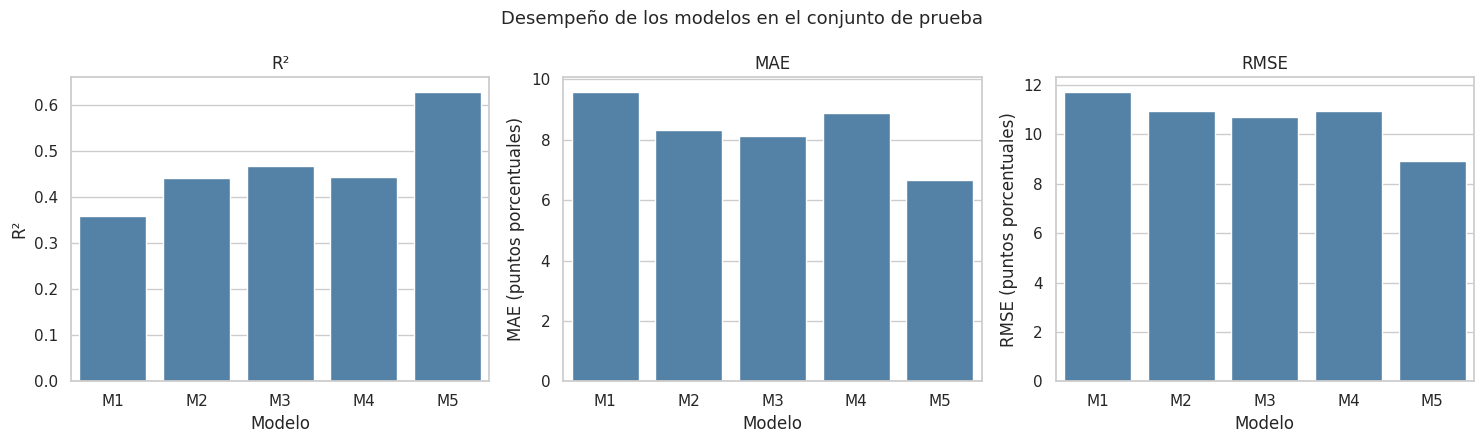

In [28]:
# Preparar resultados para graficar
df_metricas = resultados_avanzados.reset_index().rename(
    columns={"index": "Modelo"}
)

df_metricas["Modelo"] = ["M1", "M2", "M3", "M4", "M5"]

# Crear gráficos
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, metrica in zip(axes, ["R²", "MAE", "RMSE"]):

    sns.barplot(
        data=df_metricas,
        x="Modelo",
        y=metrica,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(metrica)
    ax.set_xlabel("Modelo")
    ax.set_ylabel(
        metrica if metrica == "R²"
        else f"{metrica} (puntos porcentuales)"
    )

plt.suptitle(
    "Desempeño de los modelos en el conjunto de prueba",
    fontsize=13
)

plt.tight_layout()
plt.show()

### 10.6. Comparación temporal del modelo inicial y el avanzado

Finalmente, compararemos las estimaciones de dos modelos:

- **M1:** regresión lineal utilizando únicamente temperatura.
- **M5:** Random Forest utilizando múltiples variables e ingeniería de características.

Ambos modelos fueron evaluados sobre las mismas observaciones.

Visualizaremos los primeros 14 días del conjunto de prueba para identificar las diferencias en la representación de la variabilidad temporal de la humedad relativa.

Esta comparación permitirá observar cómo cambia el desempeño cuando combinamos un algoritmo más flexible con información meteorológica adicional.

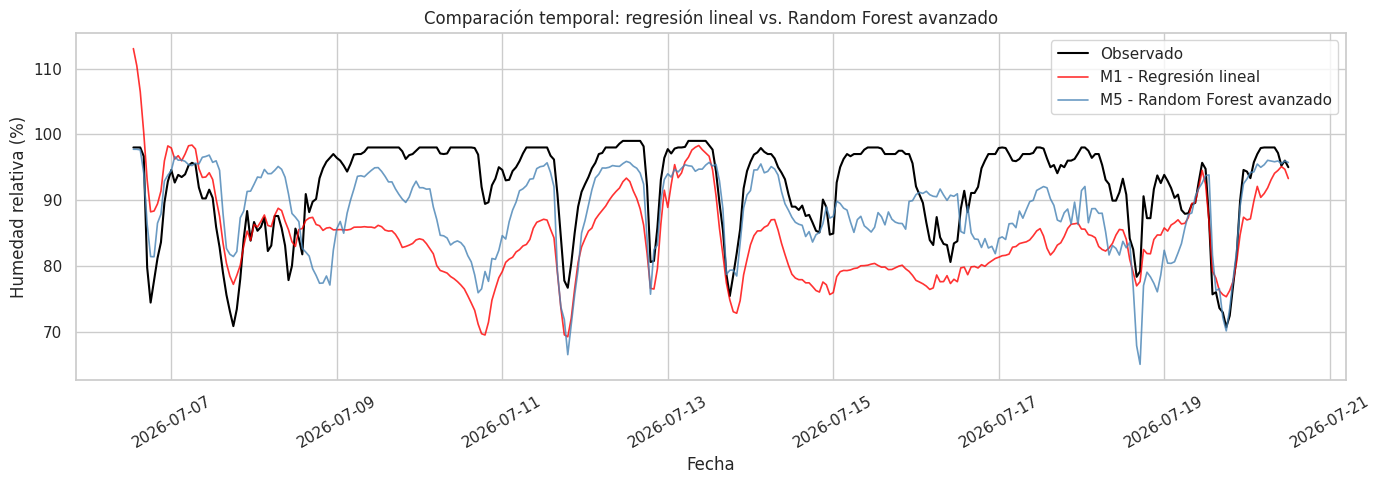

In [29]:
# Crear DataFrame de comparación
df_comparacion_av = pd.DataFrame({
    "Observado": y_test_av,
    "M1 - Regresión lineal": pred_m1,
    "M5 - RF avanzado": pred_m5
}, index=y_test_av.index)

# Seleccionar primeros 14 días
fecha_inicio = df_comparacion_av.index.min()
fecha_fin = fecha_inicio + pd.Timedelta(days=14)

df_14dias_av = df_comparacion_av.loc[
    (df_comparacion_av.index >= fecha_inicio) &
    (df_comparacion_av.index < fecha_fin)
]

# Graficar
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_14dias_av.index,
    df_14dias_av["Observado"],
    color="black",
    linewidth=1.5,
    label="Observado"
)

ax.plot(
    df_14dias_av.index,
    df_14dias_av["M1 - Regresión lineal"],
    color="red",
    linewidth=1.2,
    alpha=0.8,
    label="M1 - Regresión lineal"
)

ax.plot(
    df_14dias_av.index,
    df_14dias_av["M5 - RF avanzado"],
    color="steelblue",
    linewidth=1.2,
    alpha=0.8,
    label="M5 - Random Forest avanzado"
)

ax.set_xlabel("Fecha")
ax.set_ylabel("Humedad relativa (%)")
ax.set_title(
    "Comparación temporal: regresión lineal vs. Random Forest avanzado"
)

ax.legend()
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### 10.7. Importancia de las características en Random Forest

Una ventaja adicional de Random Forest es que permite explorar qué variables predictoras tienen mayor importancia dentro del modelo.

Hasta ahora hemos incorporado:

- Variables meteorológicas actuales.
- Variables meteorológicas de horas anteriores (rezagos).
- Variables temporales, como la hora del día y el mes.

Pero ¿todas estas características contribuyen de la misma manera a las estimaciones?

Random Forest proporciona el atributo `feature_importances_`, que permite calcular la importancia relativa de cada variable.

Esta medida se basa en cuánto contribuye cada característica a reducir los errores durante la construcción de los árboles.

Los valores se encuentran entre 0 y 1 y su suma es igual a 1.

**Importante:** una variable con mayor importancia no necesariamente tiene una relación causal con la humedad relativa.

Además, cuando existen variables correlacionadas, como la temperatura actual y sus rezagos, la importancia puede distribuirse entre ellas.

Por tanto, estos resultados deben interpretarse como una descripción del funcionamiento del modelo, no como una medida directa de la influencia física de cada variable.

,Variable,Importancia
0,Temperatura,0.8503
10,Viento_lag1,0.0163
7,Radiación_lag1,0.0147
12,Viento_lag6,0.0147
8,Radiación_lag3,0.0145
11,Viento_lag3,0.0116
6,Temperatura_lag6,0.0110
5,Temperatura_lag3,0.0109
2,Viento,0.0098
15,Presión_lag6,0.0073


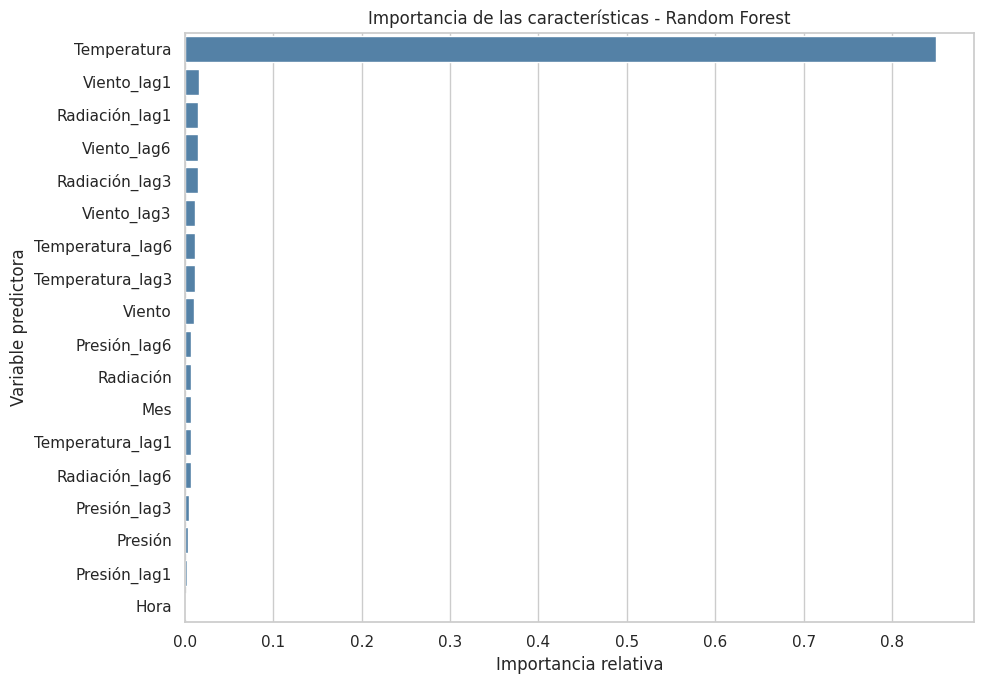

In [30]:
# Obtener importancia de las características
importancias = pd.DataFrame({
    "Variable": X_train_av.columns,
    "Importancia": m5.feature_importances_
})

# Ordenar de mayor a menor importancia
importancias = importancias.sort_values(
    by="Importancia",
    ascending=False
)

# Mostrar tabla
display(importancias.round(4))

# Visualizar importancia
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importancias,
    x="Importancia",
    y="Variable",
    color="steelblue"
)

plt.xlabel("Importancia relativa")
plt.ylabel("Variable predictora")
plt.title("Importancia de las características - Random Forest")

plt.tight_layout()
plt.show()

### 10.8. Interpretación de la importancia de las características

Observa el gráfico anterior y responde:

1. ¿Qué variable presenta la mayor importancia en Random Forest?

2. ¿Las variables meteorológicas actuales tienen mayor importancia que sus rezagos?

3. ¿Qué importancia tienen la hora del día y el mes?

4. ¿Existen variables que aportan muy poco a las divisiones realizadas por los árboles?

5. ¿Podemos afirmar que una variable con mayor importancia es la principal causa de los cambios en la humedad relativa? ¿Por qué?

**Reflexión**

La ingeniería de características permite incorporar información adicional sobre las condiciones meteorológicas y su evolución temporal.

En nuestro ejercicio, Random Forest con características avanzadas obtuvo un R² de 0.629, frente a 0.359 de la regresión lineal inicial.

Esto demuestra que combinar diferentes fuentes de información con algoritmos capaces de representar relaciones no lineales puede mejorar considerablemente las estimaciones.

Sin embargo, para desarrollar modelos destinados a aplicaciones reales, sería necesario profundizar en la selección de variables, la validación temporal y la optimización de hiperparámetros.

Estos temas forman parte de etapas más avanzadas del aprendizaje automático.

## 11. Conclusiones

En este notebook introdujimos los fundamentos del aprendizaje automático supervisado mediante una aplicación con datos meteorológicos de MeteoChillán.

Nuestro objetivo fue estimar la humedad relativa a partir de observaciones meteorológicas y comparar diferentes modelos.

### Principales aprendizajes

**1. Entrenamiento y evaluación de modelos**

Aprendimos a dividir cronológicamente las observaciones en dos conjuntos:

- Entrenamiento (70 %): utilizado para ajustar los modelos.
- Prueba (30 %): utilizado para evaluar su desempeño con observaciones no utilizadas durante el entrenamiento.

Esta separación permite evaluar la capacidad de generalización de los modelos.

**2. Regresión lineal y Random Forest**

Utilizamos dos algoritmos de aprendizaje supervisado:

- Regresión lineal: representa las relaciones mediante una ecuación lineal.
- Random Forest: combina múltiples árboles de decisión y permite representar relaciones no lineales.

Cuando utilizamos únicamente la temperatura, Random Forest obtuvo mejores resultados que la regresión lineal, aunque la mejora fue moderada.

**3. Ingeniería de características**

Posteriormente incorporamos nuevas características:

- Variables meteorológicas adicionales.
- Valores de variables registrados en horas anteriores.
- Variables temporales.

Esta etapa se conoce como ingeniería de características (*feature engineering*) y constituye una parte importante del desarrollo de modelos de aprendizaje automático.

**4. Comparación de modelos**

El mejor resultado se obtuvo con Random Forest e ingeniería de características:

| Modelo | R² | MAE | RMSE |
|---|---:|---:|---:|
| Regresión lineal inicial | 0.359 | 9.589 | 11.729 |
| Random Forest inicial | 0.441 | 8.324 | 10.952 |
| Random Forest avanzado | 0.629 | 6.651 | 8.927 |

El modelo avanzado redujo el MAE aproximadamente un 30.6 % respecto a la regresión lineal inicial.

Estos resultados muestran que combinar un algoritmo flexible con información meteorológica adicional puede mejorar considerablemente las estimaciones.

**5. Importancia de las características**

Exploramos la importancia de las variables predictoras utilizando Random Forest.

La temperatura actual presentó la mayor importancia relativa (85.03 %), mientras que las demás variables y sus rezagos contribuyeron en menor proporción.

Aprendimos que estas medidas describen el funcionamiento del modelo, pero no deben interpretarse directamente como relaciones causales.

### Limitaciones del ejercicio

Aunque obtuvimos mejoras importantes, debemos considerar algunas limitaciones:

- Disponemos de menos de un año de observaciones.
- Los periodos de entrenamiento y prueba pueden presentar condiciones estacionales diferentes.
- No realizamos una optimización sistemática de hiperparámetros.
- Los resultados corresponden a una única división temporal.
- Los rezagos deben construirse verificando que los intervalos temporales sean regulares.

Por tanto, los resultados deben considerarse una demostración introductoria y no una validación definitiva para aplicaciones operacionales.

### Reflexión final

El aprendizaje automático no consiste únicamente en seleccionar un algoritmo y entrenarlo.

El desarrollo de modelos requiere comprender el problema, preparar los datos, seleccionar variables relevantes, construir características útiles y evaluar cuidadosamente los resultados.

En este ejercicio comprobamos que la ingeniería de características y la selección del algoritmo pueden contribuir conjuntamente a mejorar las estimaciones.

**La calidad de los datos, las características utilizadas y la estrategia de evaluación son tan importantes como el algoritmo seleccionado.**